# PUSL 3205 - Developing a Tiny Transformer Language Model



## Setup

In [ ]:
!pip install -q torch datasets matplotlib gradio

import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from datasets import load_dataset

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)
torch.manual_seed(42)

Using device: cuda


## 1. Load the dataset and explore it

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

data/train-00002-of-00004-a26307300439e9(…): reconstructing file:   0%|          |  0.00B /  246MB            

... (4 outputs left out)

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 2119719
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 21990
    })
})
--- Story 0 ---
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

To

--- Story 1 ---
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.

One day, Beep was driving in the park when he saw a big tree. The tree had many leaves that were falling. Beep liked how the leaves fall and wanted to play with them. Beep drove under the tre

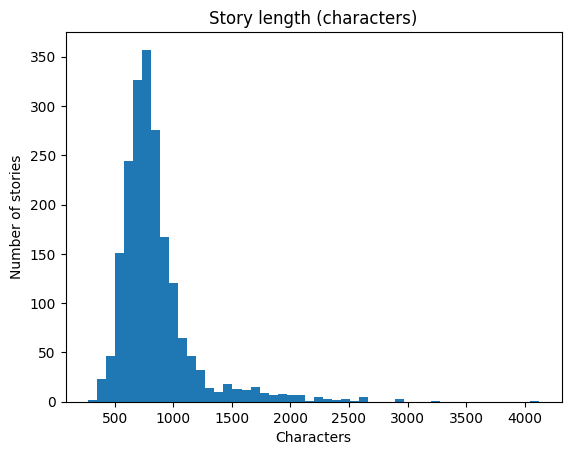

In [ ]:
ds = load_dataset("roneneldan/TinyStories")
print(ds)

for i in range(3):
    print(f"--- Story {i} ---")
    print(ds["train"][i]["text"][:400])
    print()

lengths = [len(ds["train"][i]["text"]) for i in range(2000)]
print("Average length (characters):", sum(lengths) // len(lengths))
print("Shortest:", min(lengths), "| Longest:", max(lengths))

plt.hist(lengths, bins=50)
plt.title("Story length (characters)")
plt.xlabel("Characters")
plt.ylabel("Number of stories")
plt.show()

## 2. Preprocess: small subset + character-level tokenizer

In [ ]:
NUM_STORIES = 2000
stories = ds["train"].select(range(NUM_STORIES))["text"]
text = "\n\n".join(stories)
print("Total characters:", len(text))

chars = sorted(set(text))
vocab_size = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}

def encode(s):
    return [stoi[c] for c in s if c in stoi]

def decode(ids):
    return "".join(itos[i] for i in ids)

print("Vocabulary size:", vocab_size)
print(encode("Once upon a time"))
print(decode(encode("Once upon a time")))

Total characters: 1704918
Vocabulary size: 80
[34, 59, 48, 50, 1, 66, 61, 60, 59, 1, 46, 1, 65, 54, 58, 50]
Once upon a time


## 3. Prepare training data (input x, target y shifted by one)

In [ ]:
data = torch.tensor(encode(text), dtype=torch.long)
split = int(0.9 * len(data))
train_data, val_data = data[:split], data[split:]

def get_batch(split_name, block_size, batch_size):
    d = train_data if split_name == "train" else val_data
    starts = torch.randint(len(d) - block_size - 1, (batch_size,))
    x = torch.stack([d[s: s + block_size] for s in starts])
    y = torch.stack([d[s + 1: s + block_size + 1] for s in starts])      return x.to(device), y.to(device)

x, y = get_batch("train", 8, 1)
print("Input :", decode(x[0].tolist()))
print("Target:", decode(y[0].tolist()))

Input :  see the
Target: see the 


## 4. Build the Transformer

In [ ]:
class MultiHeadAttention(nn.Module):
    """Masked multi-head self-attention."""
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.n_head = n_head
        self.qkv = nn.Linear(n_embd, 3 * n_embd)
        self.proj = nn.Linear(n_embd, n_embd)
        self.drop = nn.Dropout(dropout)

        mask = torch.tril(torch.ones(block_size, block_size))
        self.register_buffer("mask", mask.view(1, 1, block_size, block_size))

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        att = (q @ k.transpose(-2, -1)) / math.sqrt(k.size(-1))
        att = att.masked_fill(self.mask[:, :, :T, :T] == 0, float("-inf"))
        att = self.drop(F.softmax(att, dim=-1))
        out = (att @ v).transpose(1, 2).contiguous().view(B, T, C)
        return self.proj(out)


class FeedForward(nn.Module):
    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    """LayerNorm -> Attention -> residual, LayerNorm -> FeedForward -> residual."""
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = MultiHeadAttention(n_embd, n_head, block_size, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.ff = FeedForward(n_embd, dropout)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.ff(self.ln2(x))
        return x


class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, block_size, n_embd, n_head, n_layer, dropout=0.1):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, n_embd)
        self.pos_emb = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head, block_size, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.tok_emb(idx) + self.pos_emb(pos)
        x = self.blocks(x)
        logits = self.head(self.ln_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.8, top_k=None):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx

##  Initialize, train, monitor, evaluate

Parameters: 0.83M
Epoch 1/5 | train loss 2.367 | val loss 2.398 | perplexity 11.00
Epoch 2/5 | train loss 2.252 | val loss 2.293 | perplexity 9.91
Epoch 3/5 | train loss 2.118 | val loss 2.151 | perplexity 8.59
Epoch 4/5 | train loss 1.938 | val loss 1.977 | perplexity 7.22
Epoch 5/5 | train loss 1.780 | val loss 1.831 | perplexity 6.24


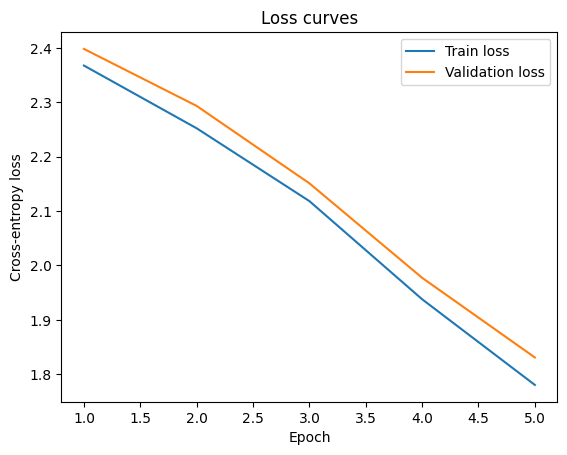

Final validation loss: 1.8309
Final perplexity     : 6.24


In [ ]:
def train_model(n_layer=4, n_head=4, n_embd=128, block_size=128, batch_size=32,
                epochs=5, steps_per_epoch=200, lr=3e-4, verbose=True):
    model = TinyTransformer(vocab_size, block_size, n_embd, n_head, n_layer).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    n_params = sum(p.numel() for p in model.parameters())
    if verbose:
        print(f"Parameters: {n_params/1e6:.2f}M")

    @torch.no_grad()
    def estimate_loss(split_name, iters=20):
        model.eval()
        losses = [model(*get_batch(split_name, block_size, batch_size))[1].item() for _ in range(iters)]
        model.train()
        return sum(losses) / len(losses)

    train_losses, val_losses = [], []
    for epoch in range(1, epochs + 1):
        for _ in range(steps_per_epoch):
            xb, yb = get_batch("train", block_size, batch_size)
            _, loss = model(xb, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        tl, vl = estimate_loss("train"), estimate_loss("val")
        train_losses.append(tl)
        val_losses.append(vl)
        if verbose:
            print(f"Epoch {epoch}/{epochs} | train loss {tl:.3f} | val loss {vl:.3f} | perplexity {math.exp(vl):.2f}")

    config = dict(vocab_size=vocab_size, block_size=block_size, n_embd=n_embd,
                  n_head=n_head, n_layer=n_layer)
    return model, train_losses, val_losses, config


model, train_losses, val_losses, config = train_model()

plt.plot(range(1, len(train_losses) + 1), train_losses, label="Train loss")
plt.plot(range(1, len(val_losses) + 1), val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Loss curves")
plt.legend()
plt.show()

print("Final validation loss:", round(val_losses[-1], 4))
print("Final perplexity     :", round(math.exp(val_losses[-1]), 2))

## 9. Generate stories

In [ ]:
def generate_story(model, prompt="Once upon a time", length=400, temperature=0.8, top_k=20):
    model.eval()
    ids = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    out = model.generate(ids, length, temperature=temperature, top_k=top_k)
    return decode(out[0].tolist())

print(generate_story(model, "Once upon a time"))

Once upon a time the ine day nound saully the like and a flook filing unts at was. She ben a frond he gard a iking to ecround the sa nelpy. She bot and dod She lowe bad the said saw the gack. The so flom wes. An and dowhe to came som, whe and wast a the mald at so file thask that and thes and cared stawns to spo to the reep a plated and spig and happy he toy said.

Tim suse was were gelt he theyy thert ham beatns


## 10. Experiment with model settings

In [ ]:

experiments = {
    "1 layer, 2 heads":  dict(n_layer=1, n_head=2),
    "2 layers, 4 heads": dict(n_layer=2, n_head=4),
    "4 layers, 4 heads": dict(n_layer=4, n_head=4),
    "4 layers, 8 heads": dict(n_layer=4, n_head=8),
}

results = {}
for name, cfg in experiments.items():
    print(f"\n=== {name} ===")
    m, tl, vl, c = train_model(epochs=3, **cfg)
    results[name] = (vl[-1], math.exp(vl[-1]))
    print("Sample:", generate_story(m, "Once upon a time", length=150).replace("\n", " "))

print("\n{:<22}{:>12}{:>14}".format("Setting", "Val loss", "Perplexity"))
for name, (l, p) in results.items():
    print("{:<22}{:>12.3f}{:>14.2f}".format(name, l, p))




=== 1 layer, 2 heads ===
Parameters: 0.24M
Epoch 1/3 | train loss 2.430 | val loss 2.475 | perplexity 11.88
Epoch 2/3 | train loss 2.334 | val loss 2.376 | perplexity 10.77
Epoch 3/3 | train loss 2.231 | val loss 2.268 | perplexity 9.66
Sample: Once upon a timer it the at ind the aske futory ad to s sund poot ineredang anouthe the ooke and as angok. cth d s way tin a s od The thanck ndecale he t thara in. Th

=== 2 layers, 4 heads ===
Parameters: 0.43M
Epoch 1/3 | train loss 2.388 | val loss 2.427 | perplexity 11.32
Epoch 2/3 | train loss 2.294 | val loss 2.335 | perplexity 10.33
Epoch 3/3 | train loss 2.208 | val loss 2.248 | perplexity 9.47
Sample: Once upon a timed pl imec. The nowaw pitt wa thaved ties ay sith the the bincifome ce erorat ay withe to mo h hin alled ack a hed rfod highey an st add he woutte tow 

=== 4 layers, 4 heads ===
Parameters: 0.83M
Epoch 1/3 | train loss 2.365 | val loss 2.400 | perplexity 11.02
Epoch 2/3 | train loss 2.237 | val loss 2.281 | perplexity 9.78

## 11. Save the trained model (weights + config + vocabulary)

In [ ]:
torch.save({"model_state": model.state_dict(), "config": config, "chars": chars},
           "tiny_transformer.pt")
print("Saved to tiny_transformer.pt")


ckpt = torch.load("tiny_transformer.pt", map_location=device)
loaded = TinyTransformer(ckpt["config"]["vocab_size"], ckpt["config"]["block_size"],
                         ckpt["config"]["n_embd"], ckpt["config"]["n_head"],
                         ckpt["config"]["n_layer"]).to(device)
loaded.load_state_dict(ckpt["model_state"])
loaded.eval()
print(generate_story(loaded, "One day", length=200))

Saved to tiny_transformer.pt
One day shay coun. They frien tusking light was was the whout sa so sput she and the fra hime campl and chemy.

Licy uple me wavis a liked up it she eell and a she baw hit was o very morse her and liked the 


## Discussion: mechanisms that improve performance

- Self-attention: every token can look at earlier tokens, so the model captures context
   (e.g. who "she" refers to) far better than fixed-window models.
- Multi-head attention: several heads learn different relationships in parallel.
- Positional embeddings: give the model word/character order, which attention lacks alone.
- Feed-forward layers + GELU: add non-linear capacity to transform each token's features.
- More data, more layers/heads, longer training, and sub-word tokenizers
   all lower loss further (at higher compute cost).

##

## Key Obersavtion

- Dataset:
TinyStories uses simple vocabulary and grammar, so a tiny model (<2.5M parameters) can learn coherent sentences.

- Stories are short (Average length (characters): 850), which suits block_size = 128

- Architecture:The causal mask (torch.tril) stops the model seeing future tokens, so it must predict the next character, which makes generation possible.

- Residual connections and LayerNorm keep gradients stable, which makes deeper stacks trainable.

- Hyperparameters:The 4-layer model reached lower loss (2.178) than the 1-layer model (2.268). Depth helped more than adding heads.

- The character-level vocabulary is small (~80), but the model spends capacity learning spelling, and the short context limits long-range story structure.